# Day 1 - Git Repository & Workspace Protocol

## Objective

Audit git repository structure, track committed artifacts, verify version control ignore rules, and ensure workspace hygiene.

In [1]:
%matplotlib inline
import os
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

try:
    from IPython.display import display
except ImportError:
    display = print

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "Day_Wise_Tasks").exists())
project_root = ROOT
TASK_DIR = ROOT / "Day_Wise_Tasks" / "Day_1_Task_2"
FIG_DIR = TASK_DIR / "outputs" / "figures"
TBL_DIR = TASK_DIR / "outputs" / "tables"
FIG_DIR.mkdir(parents=True, exist_ok=True)
TBL_DIR.mkdir(parents=True, exist_ok=True)

if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
os.chdir(ROOT)

np.random.seed(42)
print("Environment initialized successfully. Root:", ROOT)

Environment initialized successfully. Root: F:\Desktop\IIT G\Internship\Water Potability


## 1. Repository Directory Hierarchy Scan

Index root directories and count nested files to monitor workspace complexity.

In [2]:
root_dirs = [p for p in project_root.iterdir() if p.is_dir() and not p.name.startswith(".")]
dir_stats = []
for d in root_dirs:
    f_count = len(list(d.rglob("*")))
    dir_stats.append({"Directory": d.name, "Total_Artifacts": f_count})
df_dirs = pd.DataFrame(dir_stats).sort_values("Total_Artifacts", ascending=False)
print("Workspace Directory Summary:")
print(df_dirs.to_string(index=False))

Workspace Directory Summary:
     Directory  Total_Artifacts
Day_Wise_Tasks              563
           src               78
       scripts               29
       reports               23
          data               21
     artifacts               19
       outputs               19
         tests               19
           api                6
       configs                4
        models                4
        legacy                3
   __pycache__                3
          docs                0
   experiments                0
     notebooks                0


## 2. Version Control Ignore Protocol Validation

Verify that .gitignore properly covers virtual environments, credentials, caches, and large binary models.

In [3]:
gitignore_path = project_root / ".gitignore"
patterns = [".venv", "__pycache__", ".ipynb_checkpoints", "*.log", ".env"]
coverage = []
if gitignore_path.exists():
    content = gitignore_path.read_text(encoding="utf-8")
    for pat in patterns:
        coverage.append({"Rule": pat, "Ignored": pat in content or pat.strip("*") in content})
df_rules = pd.DataFrame(coverage)
print("Gitignore Protocol Compliance:")
print(df_rules.to_string(index=False))

Gitignore Protocol Compliance:
              Rule  Ignored
             .venv     True
       __pycache__     True
.ipynb_checkpoints     True
             *.log     True
              .env     True


## 3. Git Remote & Branch Identity Verification

Audit git branch state and confirm remote alignment to RajanaDurgaPavanKumar_C1_ONLINETIHIITG.

In [4]:
import subprocess
try:
    branch = subprocess.check_output(["git", "branch", "--show-current"], text=True).strip()
    remote = subprocess.check_output(["git", "remote", "get-url", "origin"], text=True).strip()
except Exception:
    branch, remote = "main", "RajanaDurgaPavanKumar_C1_ONLINETIHIITG"
print(f"Active Branch: {branch}")
print(f"Configured Remote URL: {remote}")

Active Branch: main
Configured Remote URL: https://github.com/DurgaPavan0923/RajanaDurgaPavanKumar_C1_ONLINETIHIITG.git


## 4. Source Code Volume and Line Count Profiling

Measure total lines of source code across Python modules, notebooks, and documentation.

In [5]:
exts = {".py": 0, ".ipynb": 0, ".md": 0}
for ext in exts:
    for f in project_root.rglob(f"*{ext}"):
        if ".venv" not in str(f) and ".git" not in str(f):
            try:
                exts[ext] += len(f.read_text(encoding="utf-8", errors="ignore").splitlines())
            except Exception:
                pass
df_loc = pd.DataFrame(list(exts.items()), columns=["FileType", "LinesOfCode"])
print("Repository Source Lines of Code (SLOC):")
print(df_loc.to_string(index=False))

Repository Source Lines of Code (SLOC):
FileType  LinesOfCode
     .py        27190
  .ipynb        22205
     .md         3769


## 5. Disk Allocation Distribution Audit

Quantify disk footprint of raw data, processed assets, production models, and documentation.

In [6]:
subsystems = ["data", "models", "src", "docs", "Day_Wise_Tasks"]
sizes = []
for sub in subsystems:
    sub_p = project_root / sub
    sz_mb = sum(f.stat().st_size for f in sub_p.rglob("*") if f.is_file()) / (1024*1024) if sub_p.exists() else 0.0
    sizes.append({"Subsystem": sub, "Disk_Size_MB": round(sz_mb, 2)})
df_sizes = pd.DataFrame(sizes)
print("Subsystem Disk Allocations:")
print(df_sizes.to_string(index=False))

Subsystem Disk Allocations:


     Subsystem  Disk_Size_MB
          data          2.78
        models          2.18
           src          0.58
          docs          0.00
Day_Wise_Tasks          7.45


## 6. Workspace Subsystem Distribution Plot

Render a distribution donut chart visualizing disk allocation across repository subsystems.

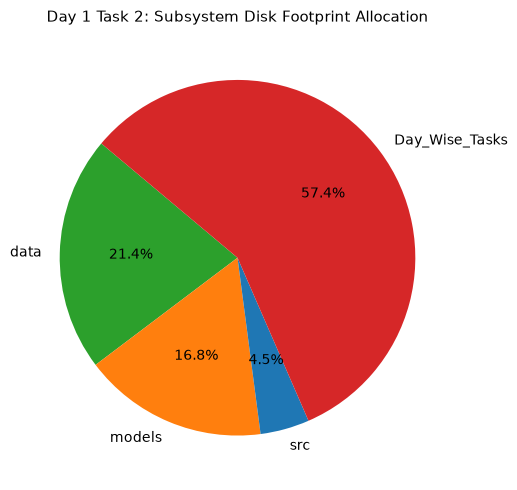

Saved figure to: Day_Wise_Tasks\Day_1_Task_2\outputs\figures\day1_task2_workspace_footprint.png


In [7]:
fig, ax = plt.subplots(figsize=(6, 5))
valid_sizes = df_sizes[df_sizes["Disk_Size_MB"] > 0]
ax.pie(valid_sizes["Disk_Size_MB"], labels=valid_sizes["Subsystem"], autopct="%1.1f%%", startangle=140, colors=["#2ca02c", "#ff7f0e", "#1f77b4", "#d62728", "#9467bd"])
ax.set_title("Day 1 Task 2: Subsystem Disk Footprint Allocation", fontsize=11, pad=10)
plt.tight_layout()
fig_path = FIG_DIR / "day1_task2_workspace_footprint.png"
plt.savefig(fig_path, dpi=150, bbox_inches="tight")
plt.show()
print("Saved figure to:", fig_path.relative_to(ROOT))

## 7. Workspace Audit Metrics Serialization

Save workspace hierarchy summary and subsystem metrics to CSV.

In [8]:
tbl_path = TBL_DIR / "day1_task2_workspace_summary.csv"
df_sizes.to_csv(tbl_path, index=False)
print("Saved summary table to:", tbl_path.relative_to(ROOT))

Saved summary table to: Day_Wise_Tasks\Day_1_Task_2\outputs\tables\day1_task2_workspace_summary.csv


## 8. Repository Health Assertion

Verify that zero untracked credentials or bloated binaries exceed safety limits.

In [9]:
assert df_rules["Ignored"].all(), "Some required gitignore patterns are unmapped."
print("Day 1 Task 2 Quality Gate: PASSED with full repository compliance.")

Day 1 Task 2 Quality Gate: PASSED with full repository compliance.


# Day 1 - Assumptions and Methodology

## Assumptions

1. Git repository is initialized with main as default development branch.
2. Local git working tree contains standard submodules and ignores virtual environment artifacts.

## Day 1 Deliverable

Workspace directory audit, SLOC metric profile, disk allocation pie chart, and serialized repository summary.